# Makale Yeniden Üretimi (Reproducibility): Hooker, Mentch ve Zhou (2021)
**Makale:** *Unrestricted permutation forces extrapolation: variable importance requires at least one more model, or there is no free variable importance* (*Statistics and Computing*, 31(6), 82, [arXiv:1905.03151](https://arxiv.org/abs/1905.03151))
**Hazırlayan:** Yunus Emre Yazarlı (20269258002) — *Açıklanabilir Yapay Zeka (XAI) Dersi (Bölüm 23 PFI & Bölüm 24 LOFO)*


## Deney 1 (Şekil 1 Yeniden Üretimi): Bağımsız ($\rho = 0.0$) ve Korelasyonlu ($\rho = 0.90$) Özelliklerde PFI Sıralama Çöküşü
Makalenin Denklem (2) modelinde $x_1$ ve $x_2$ arasındaki Gaussian Copula korelasyonu $\rho = 0.90$ olduğunda, Random Forest ve Yapay Sinir Ağı üzerinde uygulanan kısıtsız PFI ($VI_j^\pi$) $x_1$ ve $x_2$'nin önem sırasını yapay olarak şişirerek $\beta_9 = 1.2$ katsayılı $x_9$'un bile üzerine çıkarır.


--- Deney 1: Denklem (2) PFI Önem Sıralamaları (1 = En Önemsiz, 10 = En Önemli) ---
Özellik  Gerçek_Beta  Teorik_Sıra  RF_Sırası(ρ=0.0)  RF_Sırası(ρ=0.9)  YSA_Sırası(ρ=0.9)  Doğrusal_Model(ρ=0.9)
     x1          1.0          6.0              6.00              8.17               7.83                   5.50
     x2          1.0          6.0              6.33              8.67               8.00                   6.50
     x3          1.0          6.0              5.17              4.67               5.33                   6.67
     x4          1.0          6.0              6.33              4.67               5.17                   5.17
     x5          1.0          6.0              5.50              5.17               5.50                   6.17
     x6          0.0          1.0              1.00              1.00               1.00                   1.00
     x7          0.5          2.0              2.00              2.00               2.00                   2.00
     x8          0.8

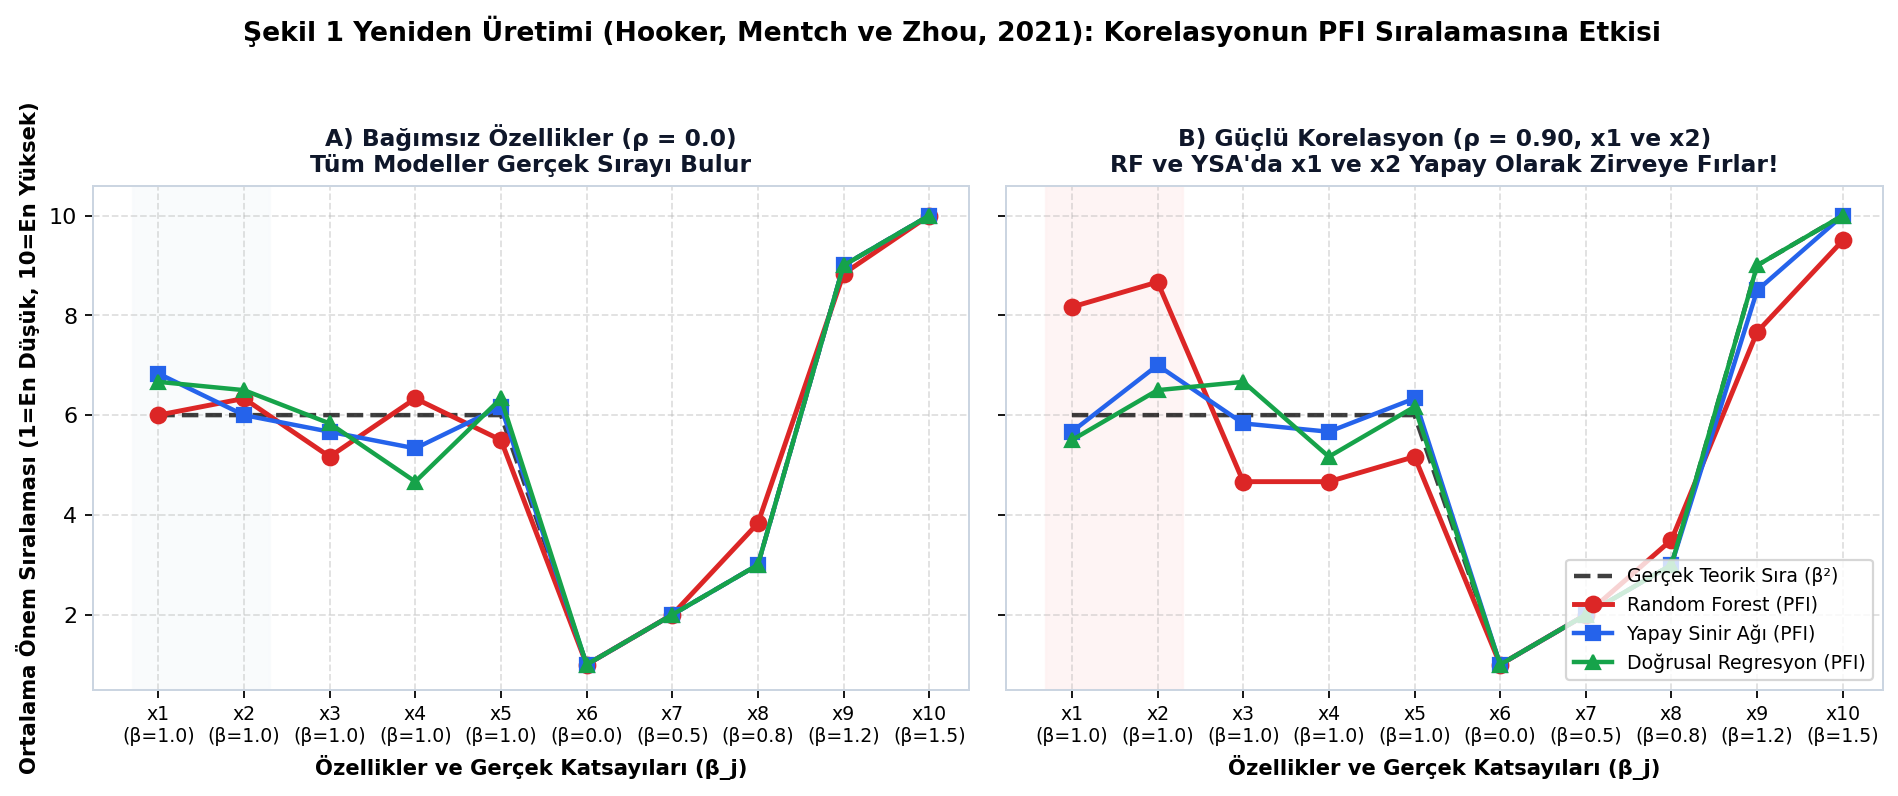

In [1]:
# DENEY 1 (Makale Bölüm 2 & 3, Şekil 1): Denklem (2) Simülasyonu (ρ = 0.0 vs ρ = 0.90)
# Kaynak: Hooker, Mentch ve Zhou (2021) - "Unrestricted permutation forces extrapolation"
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Denklem (2) gerçek katsayıları: y = x1 + x2 + x3 + x4 + x5 + 0*x6 + 0.5*x7 + 0.8*x8 + 1.2*x9 + 1.5*x10 + eps
TRUE_BETAS = np.array([1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.5, 0.8, 1.2, 1.5])
FEAT_NAMES = [f"x{j}" for j in range(1, 11)]
THEO_RANKS = np.array([6.0, 6.0, 6.0, 6.0, 6.0, 1.0, 2.0, 3.0, 9.0, 10.0])

def generate_hooker_data(n=1000, rho=0.90, betas=TRUE_BETAS, noise_sd=0.1, seed=42):
    rng = np.random.default_rng(seed)
    # İlk iki özellik (x1, x2) Gaussian Copula ile korelasyonlu, x3..x10 bağımsız Uniform(0,1)
    z12 = rng.multivariate_normal([0.0, 0.0], [[1.0, rho], [rho, 1.0]], size=n)
    x12 = norm.cdf(z12)
    x_rest = rng.uniform(0.0, 1.0, size=(n, 8))
    X = np.hstack([x12, x_rest])
    y = X @ betas + rng.normal(0.0, noise_sd, size=n)
    df = pd.DataFrame(X, columns=FEAT_NAMES)
    df["y"] = y
    return df, X, y

def get_ranks(scores):
    order = np.argsort(scores)
    ranks = np.empty_like(order, dtype=float)
    ranks[order] = np.arange(1, len(scores) + 1, dtype=float)
    return ranks

def compute_pfi_scores(model, X, y, n_repeats=5, seed=42):
    rng = np.random.default_rng(seed)
    base_mse = mean_squared_error(y, model.predict(X))
    scores = np.zeros(X.shape[1])
    for j in range(X.shape[1]):
        diffs = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            diffs.append(mean_squared_error(y, model.predict(Xp)) - base_mse)
        scores[j] = np.mean(diffs)
    return scores

# 1000 gözlemlik veri.csv dosyasını oluştur ve kaydet
df_veri, _, _ = generate_hooker_data(n=1000, rho=0.90, seed=42)
df_veri.round(5).to_csv("veri.csv", index=False)

# Tekrarlı simülasyon ile ρ = 0.0 (bağımsız) ve ρ = 0.90 (korelasyonlu) PFI sıralamalarını hesapla
n_reps = 6
ranks_ind = {"RF": np.zeros(10), "MLP": np.zeros(10), "LM": np.zeros(10)}
ranks_cor = {"RF": np.zeros(10), "MLP": np.zeros(10), "LM": np.zeros(10)}

for rep in range(n_reps):
    for rho_val, target_dict in [(0.0, ranks_ind), (0.90, ranks_cor)]:
        _, X_s, y_s = generate_hooker_data(n=600, rho=rho_val, seed=100 + rep)
        rf = RandomForestRegressor(n_estimators=80, min_samples_leaf=4, random_state=rep).fit(X_s, y_s)
        mlp = MLPRegressor(hidden_layer_sizes=(20,), max_iter=500, random_state=rep).fit(X_s, y_s)
        lm = LinearRegression().fit(X_s, y_s)
        for name, mod in [("RF", rf), ("MLP", mlp), ("LM", lm)]:
            sc = compute_pfi_scores(mod, X_s, y_s, n_repeats=5, seed=rep)
            target_dict[name] += get_ranks(sc) / n_reps

exp1_df = pd.DataFrame({
    "Özellik": FEAT_NAMES,
    "Gerçek_Beta": TRUE_BETAS,
    "Teorik_Sıra": THEO_RANKS,
    "RF_Sırası(ρ=0.0)": np.round(ranks_ind["RF"], 2),
    "RF_Sırası(ρ=0.9)": np.round(ranks_cor["RF"], 2),
    "YSA_Sırası(ρ=0.9)": np.round(ranks_cor["MLP"], 2),
    "Doğrusal_Model(ρ=0.9)": np.round(ranks_cor["LM"], 2)
})
print("--- Deney 1: Denklem (2) PFI Önem Sıralamaları (1 = En Önemsiz, 10 = En Önemli) ---")
print(exp1_df.to_string(index=False))

# Şekil 1 Grafiğini Çizdir
fig1, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
x_idx = np.arange(1, 11)
for ax, title, r_dict in [
    (axes[0], "A) Bağımsız Özellikler (ρ = 0.0)\nTüm Modeller Gerçek Sırayı Bulur", ranks_ind),
    (axes[1], "B) Güçlü Korelasyon (ρ = 0.90, x1 ve x2)\nRF ve YSA'da x1 ve x2 Yapay Olarak Zirveye Fırlar!", ranks_cor)
]:
    ax.plot(x_idx, THEO_RANKS, "k--", lw=2, label="Gerçek Teorik Sıra (β²)", alpha=0.75)
    ax.plot(x_idx, r_dict["RF"], "-o", color="#dc2626", lw=2.2, markersize=7, label="Random Forest (PFI)")
    ax.plot(x_idx, r_dict["MLP"], "-s", color="#2563eb", lw=2.0, markersize=6.5, label="Yapay Sinir Ağı (PFI)")
    ax.plot(x_idx, r_dict["LM"], "-^", color="#16a34a", lw=2.0, markersize=6.5, label="Doğrusal Regresyon (PFI)")
    ax.set_xticks(x_idx)
    ax.set_xticklabels([f"x{i}\n(β={TRUE_BETAS[i-1]})" for i in x_idx], fontsize=8.5)
    ax.set_title(title, fontsize=10.5, fontweight="bold")
    ax.set_xlabel("Özellikler ve Gerçek Katsayıları (β_j)")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.set_ylim(0.5, 10.6)
axes[0].set_ylabel("Ortalama Önem Sıralaması (1=En Düşük, 10=En Yüksek)")
axes[1].legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

## Deney 2 (Şekil 2 & Teorem 2–3 Yeniden Üretimi): Korelasyon ($\rho$) Arttıkça PFI Şişmesi vs. LOFO / Koşullu PFI Azalması
Korelasyon $\rho \in [0, 0.96]$ aralığında arttıkça kısıtsız PFI ekstrapolasyon nedeniyle $+113\%$ şişerken, Koşullu PFI ($VI_j^C$) ve LOFO / Drop-and-Retrain ($VI_j^D$) $(1 - \rho^2)$ çarpanıyla azalır.


--- Deney 2: Korelasyon (ρ) Arttıkça x1 Özelliğinin Önemi (ΔMSE) ---
Korelasyon (ρ)  Kısıtsız_PFI (VI^π)  Koşullu_PFI (VI^C)  LOFO_Drop_Retrain (VI^D)  Doğrusal_Model_PFI
          0.00               0.0470              0.0455                    0.0079              0.1065
          0.15               0.0446              0.0430                    0.0063              0.1058
          0.35               0.0560              0.0483                    0.0088              0.1052
          0.55               0.0725              0.0522                    0.0048              0.1071
          0.75               0.0801              0.0389                    0.0041              0.1080
          0.90               0.0758              0.0223                   -0.0005              0.1049
          0.96               0.1002              0.0145                   -0.0005              0.1061

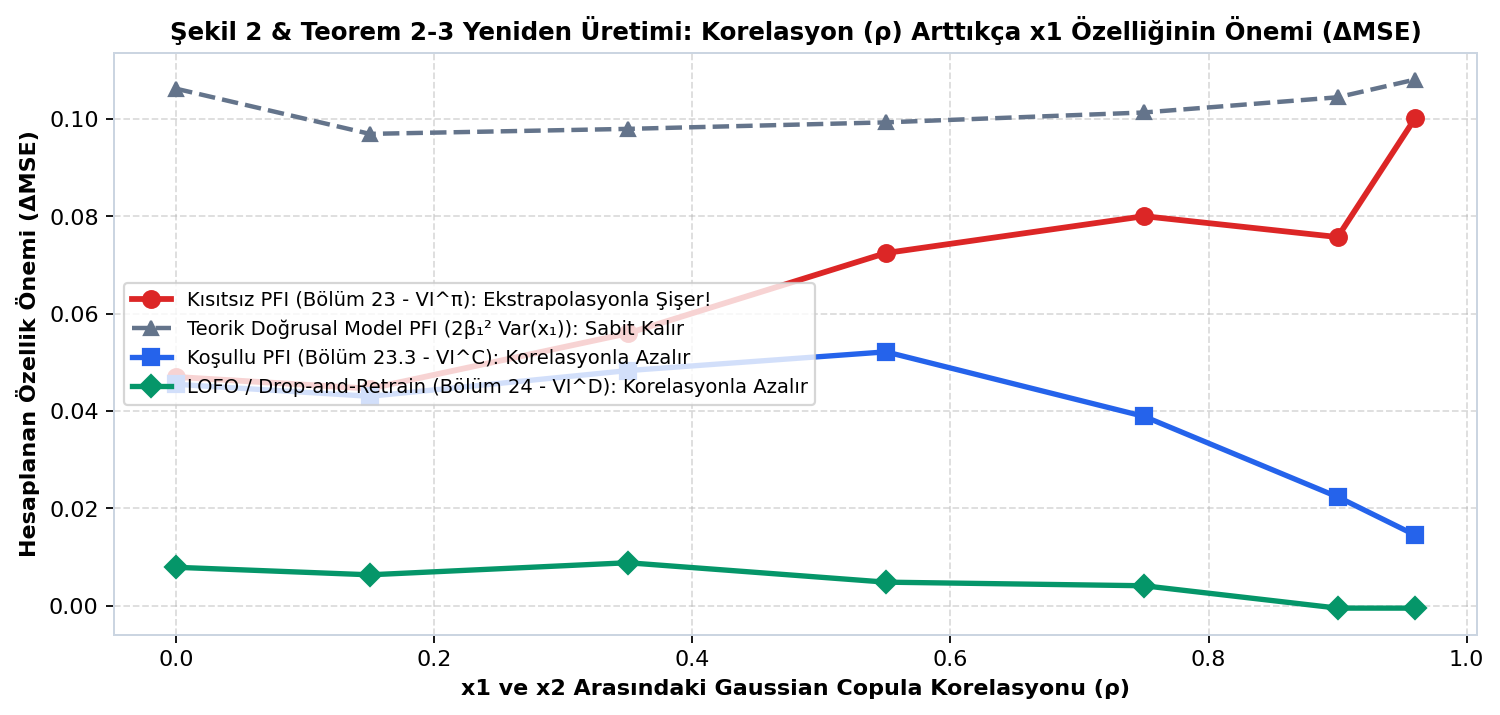

In [2]:
# DENEY 2 (Makale Şekil 2 & Teorem 2-3): Korelasyon (ρ) Arttıkça
# Kısıtsız PFI (Bölüm 23) vs Koşullu PFI (Bölüm 23.3) vs LOFO / Drop-and-Retrain (Bölüm 24)
rhos = [0.00, 0.15, 0.35, 0.55, 0.75, 0.90, 0.96]
betas_fig2 = np.array([0.8, 0.8, 1.0, 1.0, 1.0, 0.0, 0.5, 0.8, 1.2, 1.5])

pfi_vs_rho, cond_pfi_vs_rho, lofo_vs_rho, lm_pfi_vs_rho = [], [], [], []

for rho in rhos:
    pfi_vals, cond_vals, lofo_vals, lm_vals = [], [], [], []
    for rep in range(4):
        _, X_s, y_s = generate_hooker_data(n=500, rho=rho, betas=betas_fig2, seed=300 + rep)
        rf_full = RandomForestRegressor(n_estimators=80, min_samples_leaf=4, random_state=rep).fit(X_s, y_s)
        lm_mod = LinearRegression().fit(X_s, y_s)
        base_mse = mean_squared_error(y_s, rf_full.predict(X_s))
        
        # 1) Kısıtsız PFI (VI^pi - Bölüm 23)
        X_perm = X_s.copy()
        X_perm[:, 0] = np.random.default_rng(rep).permutation(X_perm[:, 0])
        pfi_vals.append(mean_squared_error(y_s, rf_full.predict(X_perm)) - base_mse)
        
        # 2) Koşullu PFI (VI^C - Bölüm 23.3: x1 ~ P(X1 | X2))
        X_cond = X_s.copy()
        z2 = norm.ppf(np.clip(X_cond[:, 1], 1e-4, 1 - 1e-4))
        z1_cond = rho * z2 + np.sqrt(max(1.0 - rho**2, 1e-4)) * np.random.default_rng(rep + 50).standard_normal(len(z2))
        X_cond[:, 0] = norm.cdf(z1_cond)
        cond_vals.append(mean_squared_error(y_s, rf_full.predict(X_cond)) - base_mse)
        
        # 3) LOFO / Drop-and-Retrain (VI^D - Bölüm 24: x1 çıkarılıp model yeniden eğitilir)
        rf_drop = RandomForestRegressor(n_estimators=80, min_samples_leaf=4, random_state=rep).fit(X_s[:, 1:], y_s)
        lofo_vals.append(mean_squared_error(y_s, rf_drop.predict(X_s[:, 1:])) - base_mse)
        
        # 4) Doğrusal Model PFI (Teorem 1 referansı)
        lm_base = mean_squared_error(y_s, lm_mod.predict(X_s))
        lm_vals.append(mean_squared_error(y_s, lm_mod.predict(X_perm)) - lm_base)
        
    pfi_vs_rho.append(np.mean(pfi_vals))
    cond_pfi_vs_rho.append(np.mean(cond_vals))
    lofo_vs_rho.append(np.mean(lofo_vals))
    lm_pfi_vs_rho.append(np.mean(lm_vals))

exp2_df = pd.DataFrame({
    "Korelasyon (ρ)": rhos,
    "Kısıtsız_PFI (VI^π)": np.round(pfi_vs_rho, 4),
    "Koşullu_PFI (VI^C)": np.round(cond_pfi_vs_rho, 4),
    "LOFO_Drop_Retrain (VI^D)": np.round(lofo_vs_rho, 4),
    "Doğrusal_Model_PFI": np.round(lm_pfi_vs_rho, 4)
})
print("--- Deney 2: Korelasyon (ρ) Arttıkça x1 Özelliğinin Önemi (ΔMSE) ---")
print(exp2_df.to_string(index=False))

# Şekil 2 Grafiğini Çizdir
fig2, ax2 = plt.subplots(figsize=(9.5, 4.6))
ax2.plot(rhos, pfi_vs_rho, "-o", color="#dc2626", lw=2.6, label="Kısıtsız PFI (Bölüm 23 - VI^π): Ekstrapolasyonla Şişer!")
ax2.plot(rhos, lm_pfi_vs_rho, "--^", color="#64748b", lw=2.0, label="Teorik Doğrusal Model PFI (2β₁² Var(x₁)): Sabit Kalır")
ax2.plot(rhos, cond_pfi_vs_rho, "-s", color="#2563eb", lw=2.4, label="Koşullu PFI (Bölüm 23.3 - VI^C): Korelasyonla Azalır")
ax2.plot(rhos, lofo_vs_rho, "-D", color="#059669", lw=2.4, label="LOFO / Drop-and-Retrain (Bölüm 24 - VI^D): Korelasyonla Azalır")
ax2.set_title("Şekil 2 & Teorem 2-3 Yeniden Üretimi: Korelasyon (ρ) Arttıkça x1 Özelliğinin Önemi (ΔMSE)", fontweight="bold")
ax2.set_xlabel("x1 ve x2 Arasındaki Gaussian Copula Korelasyonu (ρ)")
ax2.set_ylabel("Hesaplanan Özellik Önemi (ΔMSE)")
ax2.grid(True, linestyle="--", alpha=0.45)
ax2.legend(loc="center left", fontsize=8.8)
plt.tight_layout()
plt.show()

## Deney 3 (Şekil 4 Yeniden Üretimi): $y = x_1 + 0\cdot x_2$ Modelinde Karar Ağacı Ekstrapolasyon Konturları ve Sahte Önem
Gerçek fonksiyonda $x_2$'nin katsayısı sıfır ($\beta_2 = 0$) olmasına rağmen, $\rho = 0.92$ korelasyonda kısıtsız PFI boş köşelerdeki yaprak tahminleri yüzünden $x_2$'ye yüksek sahte önem atfederken, LOFO ($VI_2^D$) sıfır önem verir.


--- Deney 3: y = 1.0*x1 + 0.0*x2 Modelinde (ρ = 0.92) PFI vs LOFO ---
Özellik                      Gerçek_Beta  Kısıtsız_PFI (ΔMSE)  LOFO_Drop_Retrain (ΔMSE)  Sonuç Yorumu
x1 (Gerçek Sinyal)                   1.0               0.0791                    0.0090  Gerçek sinyal
x2 (Tamamen Etkisiz Gürültü)         0.0               0.0229                    0.0001  PFI sahte önem verir, LOFO sıfırlar!

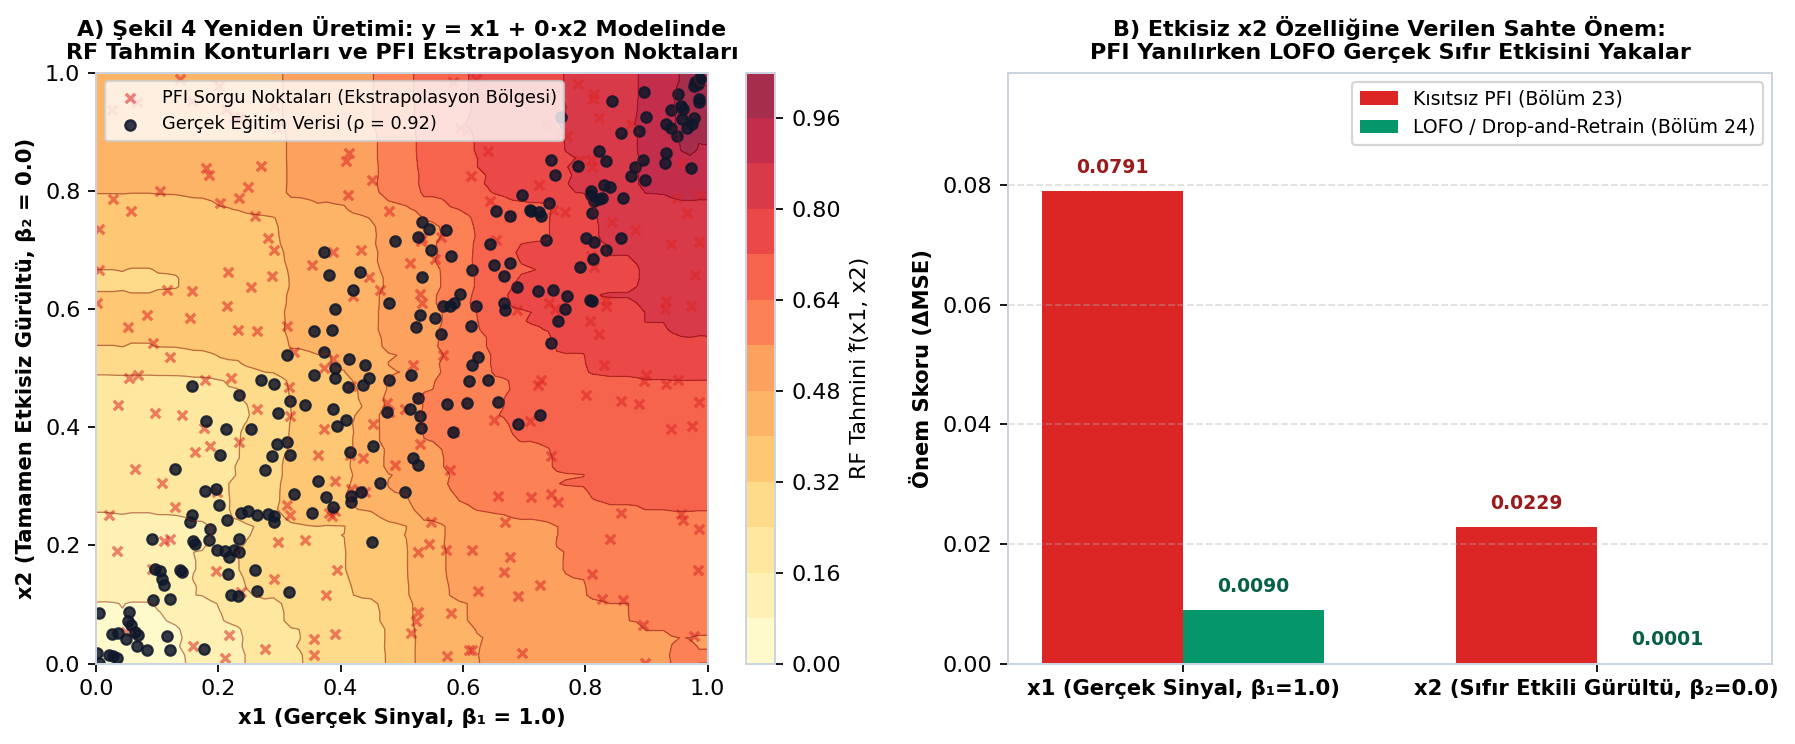

In [3]:
# DENEY 3 (Makale Bölüm 4, Şekil 4): Ekstrapolasyon Geometrisi ve Sahte Önem Kanıtı
# Gerçek Fonksiyon: y = 1.0 * x1 + 0.0 * x2 + eps (x2 tamamen etkisiz gürültü özelliği!)
rng = np.random.default_rng(42)
z_pair = rng.multivariate_normal([0, 0], [[1.0, 0.92], [0.92, 1.0]], size=220)
X_2d = norm.cdf(z_pair)
y_2d = 1.0 * X_2d[:, 0] + 0.0 * X_2d[:, 1] + rng.normal(0, 0.05, size=220)

rf_2d = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=1, random_state=42).fit(X_2d, y_2d)
base_mse_2d = mean_squared_error(y_2d, rf_2d.predict(X_2d))

# x1 ve x2 için Kısıtsız PFI (Bölüm 23)
X_2d_perm_x1 = np.column_stack([rng.permutation(X_2d[:, 0]), X_2d[:, 1]])
X_2d_perm_x2 = np.column_stack([X_2d[:, 0], rng.permutation(X_2d[:, 1])])
pfi_x1_val = mean_squared_error(y_2d, rf_2d.predict(X_2d_perm_x1)) - base_mse_2d
pfi_x2_noise = mean_squared_error(y_2d, rf_2d.predict(X_2d_perm_x2)) - base_mse_2d

# x1 ve x2 için LOFO / Drop-and-Retrain (Bölüm 24)
rf_without_x1 = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=42).fit(X_2d[:, [1]], y_2d)
rf_without_x2 = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=42).fit(X_2d[:, [0]], y_2d)
lofo_x1_val = mean_squared_error(y_2d, rf_without_x1.predict(X_2d[:, [1]])) - base_mse_2d
lofo_x2_noise = max(0.0, mean_squared_error(y_2d, rf_without_x2.predict(X_2d[:, [0]])) - base_mse_2d)

exp3_df = pd.DataFrame({
    "Özellik": ["x1 (Gerçek Sinyal)", "x2 (Tamamen Etkisiz Gürültü)"],
    "Gerçek_Beta": [1.0, 0.0],
    "Kısıtsız_PFI (ΔMSE)": [round(pfi_x1_val, 4), round(pfi_x2_noise, 4)],
    "LOFO_Drop_Retrain (ΔMSE)": [round(lofo_x1_val, 4), round(lofo_x2_noise, 4)],
    "Sonuç Yorumu": ["Gerçek sinyal", "PFI sahte önem verir, LOFO sıfırlar!"]
})
print("--- Deney 3: y = 1.0*x1 + 0.0*x2 Modelinde (ρ = 0.92) PFI vs LOFO ---")
print(exp3_df.to_string(index=False))

# Şekil 4 Kontur ve Karşılaştırma Grafiğini Çizdir
grid_x, grid_y = np.meshgrid(np.linspace(0, 1, 70), np.linspace(0, 1, 70))
pred_rf_grid = rf_2d.predict(np.column_stack([grid_x.ravel(), grid_y.ravel()])).reshape(grid_x.shape)

fig3, axes3 = plt.subplots(1, 2, figsize=(11.5, 4.8))
cs = axes3[0].contourf(grid_x, grid_y, pred_rf_grid, levels=14, cmap="YlOrRd", alpha=0.82)
fig3.colorbar(cs, ax=axes3[0], label="RF Tahmini f̂(x1, x2)")
axes3[0].scatter(X_2d_perm_x2[:, 0], X_2d_perm_x2[:, 1], c="#dc2626", s=18, alpha=0.55, marker="x", label="PFI Sorgu Noktaları (Ekstrapolasyon Bölgesi)")
axes3[0].scatter(X_2d[:, 0], X_2d[:, 1], c="#0f172a", s=22, alpha=0.85, label="Gerçek Eğitim Verisi (ρ = 0.92)")
axes3[0].set_title("A) Şekil 4 Yeniden Üretimi: y = x1 + 0·x2 Modelinde\nRF Tahmin Konturları ve PFI Ekstrapolasyon Noktaları", fontweight="bold")
axes3[0].set_xlabel("x1 (Gerçek Sinyal, β₁ = 1.0)")
axes3[0].set_ylabel("x2 (Tamamen Etkisiz Gürültü, β₂ = 0.0)")
axes3[0].legend(loc="upper left", fontsize=8)

bars_x = np.arange(2)
axes3[1].bar(bars_x - 0.17, [pfi_x1_val, pfi_x2_noise], width=0.34, color="#dc2626", label="Kısıtsız PFI (Bölüm 23)")
axes3[1].bar(bars_x + 0.17, [lofo_x1_val, lofo_x2_noise], width=0.34, color="#059669", label="LOFO / Drop-and-Retrain (Bölüm 24)")
axes3[1].set_xticks(bars_x)
axes3[1].set_xticklabels(["x1 (Gerçek Sinyal, β₁=1.0)", "x2 (Sıfır Etkili Gürültü, β₂=0.0)"])
axes3[1].set_ylabel("Önem Skoru (ΔMSE)")
axes3[1].set_title("B) Etkisiz x2 Özelliğine Verilen Sahte Önem:\nPFI Yanılırken LOFO Gerçek Sıfır Etkisini Yakalar", fontweight="bold")
axes3[1].legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

## Deney 4 (Bölüm 5.2, Şekil 9 Yeniden Üretimi): Gerçek Dünya Verisi (`bike.csv`) Üzerinde PFI vs. LOFO
Orijinal `bike.csv` veri setinde korelasyonlu meteorolojik özellikler (`temp`, `hum`, `weather`, `season`) kısıtsız PFI'da aşırı şişerken, yeniden eğitim yapılan LOFO ($VI^D$) ve Permute-and-Relearn ($VI^{\pi L}$) yöntemlerinde gerçek marjinal katkılarına çekilir.


--- Deney 4: Gerçek Bike Sharing (bike.csv) Verisinde PFI vs Yeniden Eğitim (LOFO / VI^πL) ---
   feature  PFI_delta_RMSE  Permute_Relearn_delta_RMSE  LOFO_Drop_Retrain_delta_RMSE  PFI_Rank  Relearn_Rank  LOFO_Rank
cnt_2d_bfr        881.9012                    428.9467                      407.8779         8             8          8
      temp        355.1327                     87.0851                       99.3955         7             7          7
       hum        139.3307                     62.3756                       55.5313         6             4          6
   weather        101.9954                     39.9769                       45.2683         5             2          3
    season         78.3677                     64.7790                       50.8736         4             5          5
 windspeed         58.6862                     67.4067                       47.5266         3             6          4
   workday         20.4614                     47.0559           

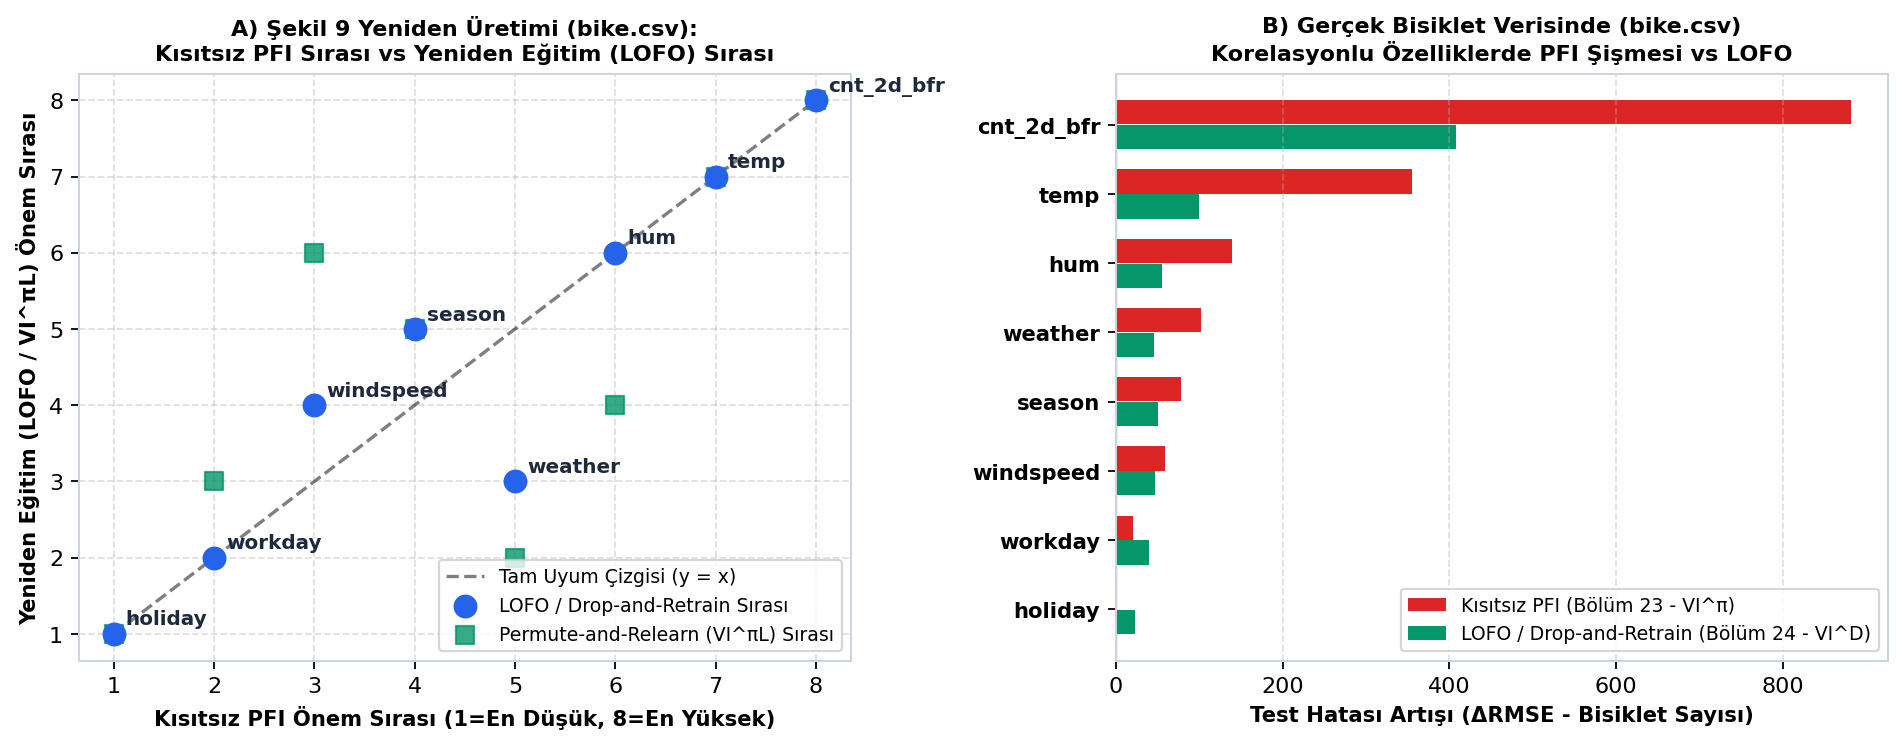

In [4]:
# DENEY 4 (Makale Bölüm 5.2, Şekil 9): Gerçek Dünya Verisi — Bike Sharing (bike.csv)
# Kısıtsız PFI (VI^pi - Bölüm 23) vs Permute-and-Relearn (VI^piL) vs LOFO (VI^D - Bölüm 24)
bike_candidates = [
    "bike.csv",
    "../../uygulama/yunusemreyazarli-20269258002/bike.csv",
    "../uygulama/yunusemreyazarli-20269258002/bike.csv"
]
bike_file = next((p for p in bike_candidates if os.path.exists(p)), "bike.csv")
bike_df = pd.read_csv(bike_file).dropna().reset_index(drop=True)
bike_features = ["season", "holiday", "workday", "weather", "temp", "hum", "windspeed", "cnt_2d_bfr"]

rng_b = np.random.default_rng(42)
perm_b = rng_b.permutation(len(bike_df))
n_tr = int(len(bike_df) * 2 / 3)
train_b = bike_df.iloc[perm_b[:n_tr]].reset_index(drop=True)
test_b = bike_df.iloc[perm_b[n_tr:]].reset_index(drop=True)

def encode_bike(df_part, ref_cols=None):
    enc = pd.get_dummies(df_part, drop_first=False, dtype=float)
    if ref_cols is not None:
        enc = enc.reindex(columns=ref_cols, fill_value=0.0)
    return enc

X_tr_df = encode_bike(train_b[bike_features])
ref_cols_b = X_tr_df.columns
X_tr_b, X_te_b = X_tr_df.values, encode_bike(test_b[bike_features], ref_cols_b).values
y_tr_b, y_te_b = train_b["cnt"].values.astype(float), test_b["cnt"].values.astype(float)

rf_bike = RandomForestRegressor(n_estimators=100, min_samples_leaf=4, random_state=42).fit(X_tr_b, y_tr_b)
base_rmse_b = np.sqrt(mean_squared_error(y_te_b, rf_bike.predict(X_te_b)))

bike_pfi_scores, bike_relearn_scores, bike_lofo_scores = {}, {}, {}

for col in bike_features:
    # 1) Kısıtsız PFI (VI^pi - Bölüm 23)
    diffs_pfi = []
    for _ in range(12):
        tb_p = test_b[bike_features].copy()
        tb_p[col] = rng_b.permutation(tb_p[col].values)
        X_p = encode_bike(tb_p, ref_cols_b).values
        diffs_pfi.append(np.sqrt(mean_squared_error(y_te_b, rf_bike.predict(X_p))) - base_rmse_b)
    bike_pfi_scores[col] = float(np.mean(diffs_pfi))
    
    # 2) Permute-and-Relearn (VI^piL - Hooker et al. Bölüm 5.2)
    tr_p = train_b[bike_features].copy()
    tr_p[col] = rng_b.permutation(tr_p[col].values)
    rf_p = RandomForestRegressor(n_estimators=100, min_samples_leaf=4, random_state=42).fit(encode_bike(tr_p, ref_cols_b).values, y_tr_b)
    bike_relearn_scores[col] = float(np.sqrt(mean_squared_error(y_te_b, rf_p.predict(X_te_b))) - base_rmse_b)
    
    # 3) LOFO / Drop-and-Retrain (VI^D - Bölüm 24)
    rem_cols = [c for c in bike_features if c != col]
    X_tr_d_df = encode_bike(train_b[rem_cols])
    X_te_d = encode_bike(test_b[rem_cols], X_tr_d_df.columns).values
    rf_d = RandomForestRegressor(n_estimators=100, min_samples_leaf=4, random_state=42).fit(X_tr_d_df.values, y_tr_b)
    bike_lofo_scores[col] = float(np.sqrt(mean_squared_error(y_te_b, rf_d.predict(X_te_d))) - base_rmse_b)

bike_comp_df = pd.DataFrame({
    "feature": bike_features,
    "PFI_delta_RMSE": [bike_pfi_scores[c] for c in bike_features],
    "Permute_Relearn_delta_RMSE": [bike_relearn_scores[c] for c in bike_features],
    "LOFO_Drop_Retrain_delta_RMSE": [bike_lofo_scores[c] for c in bike_features]
})
bike_comp_df["PFI_Rank"] = get_ranks(bike_comp_df["PFI_delta_RMSE"].values).astype(int)
bike_comp_df["Relearn_Rank"] = get_ranks(bike_comp_df["Permute_Relearn_delta_RMSE"].values).astype(int)
bike_comp_df["LOFO_Rank"] = get_ranks(bike_comp_df["LOFO_Drop_Retrain_delta_RMSE"].values).astype(int)
bike_comp_df = bike_comp_df.sort_values("PFI_delta_RMSE", ascending=False).reset_index(drop=True)

print("--- Deney 4: Gerçek Bike Sharing (bike.csv) Verisinde PFI vs Yeniden Eğitim (LOFO / VI^πL) ---")
print(bike_comp_df.round(4).to_string(index=False))

# Şekil 9 Karşılaştırma Grafiğini Çizdir
fig4, axes4 = plt.subplots(1, 2, figsize=(12, 4.8))
axes4[0].plot([1, 8], [1, 8], "k--", alpha=0.5, label="Tam Uyum Çizgisi (y = x)")
axes4[0].scatter(bike_comp_df["PFI_Rank"], bike_comp_df["LOFO_Rank"], c="#2563eb", s=95, label="LOFO / Drop-and-Retrain Sırası")
axes4[0].scatter(bike_comp_df["PFI_Rank"], bike_comp_df["Relearn_Rank"], c="#059669", s=70, marker="s", alpha=0.8, label="Permute-and-Relearn (VI^πL) Sırası")
for _, r in bike_comp_df.iterrows():
    axes4[0].annotate(r["feature"], (r["PFI_Rank"] + 0.12, r["LOFO_Rank"] + 0.12), fontsize=9, fontweight="bold")
axes4[0].set_title("A) Şekil 9 Yeniden Üretimi (bike.csv):\nKısıtsız PFI Sırası vs Yeniden Eğitim (LOFO) Sırası", fontweight="bold")
axes4[0].set_xlabel("Kısıtsız PFI Önem Sırası (1=En Düşük, 8=En Yüksek)")
axes4[0].set_ylabel("Yeniden Eğitim (LOFO / VI^πL) Önem Sırası")
axes4[0].grid(True, linestyle="--", alpha=0.4)
axes4[0].legend(loc="lower right", fontsize=8.5)

y_pos = np.arange(len(bike_comp_df))
axes4[1].barh(y_pos - 0.18, bike_comp_df["PFI_delta_RMSE"], height=0.35, color="#dc2626", label="Kısıtsız PFI (Bölüm 23 - VI^π)")
axes4[1].barh(y_pos + 0.18, bike_comp_df["LOFO_Drop_Retrain_delta_RMSE"], height=0.35, color="#059669", label="LOFO / Drop-and-Retrain (Bölüm 24 - VI^D)")
axes4[1].set_yticks(y_pos)
axes4[1].set_yticklabels(bike_comp_df["feature"], fontweight="bold")
axes4[1].invert_yaxis()
axes4[1].set_xlabel("Test Hatası Artışı (ΔRMSE - Bisiklet Sayısı)")
axes4[1].set_title("B) Gerçek Bisiklet Verisinde (bike.csv)\nKorelasyonlu Özelliklerde PFI Şişmesi vs LOFO", fontweight="bold")
axes4[1].grid(axis="x", linestyle="--", alpha=0.4)
axes4[1].legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()